Retrieve and search (Appendix C.3–C.4)

Reproduce the book’s retrieval patterns on your table: a filtered SELECT with WHERE, an ORDER BY, and a text search using LIKE with wildcards (for example, every customer whose name contains a chosen letter pair). Finish by pulling one query’s result into pandas and charting it.

Deliverable: three working queries with visible results, plus one labeled chart born from a query.

--- Filtered & Sorted Query Results ---


,name,city,loyalty_score
0,Sam Richardson,Seattle,4.9
1,Caleb Hearon,Los Angeles,4.8
2,Jennifer Connolley,Boston,4.6
3,Tim Robinson,San Francisco,4.2
4,George Miller,New York,4.1



--- Text Search Results (LIKE '%li%') ---


,id,name,city,loyalty_score


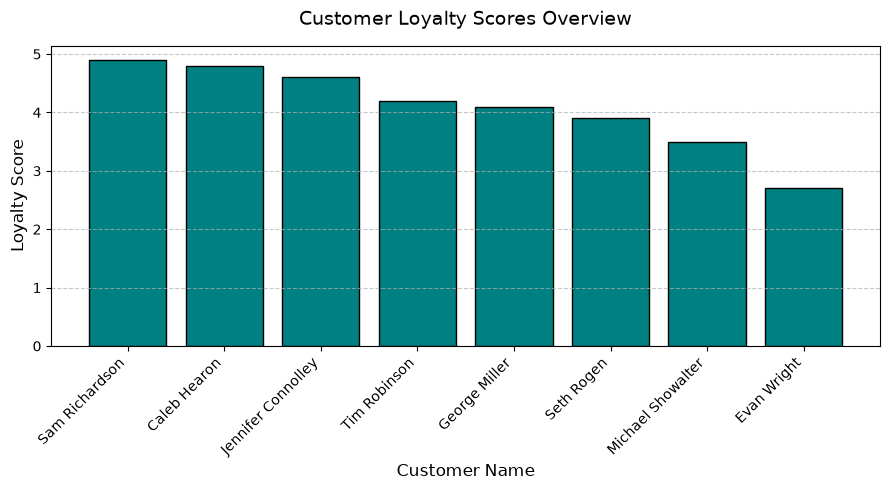

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect('lab2.db')

query_filtered = """
SELECT name, city, loyalty_score 
FROM customers 
WHERE loyalty_score > 4.0 
ORDER BY loyalty_score DESC;
"""
df_filtered = pd.read_sql(query_filtered, con)
print("--- Filtered & Sorted Query Results ---")
display(df_filtered)

query_like = """
SELECT id, name, city, loyalty_score 
FROM customers 
WHERE name LIKE '%li%';
"""
df_like = pd.read_sql(query_like, con)
print("\n--- Text Search Results (LIKE '%li%') ---")
display(df_like)

query_chart = """
SELECT name, loyalty_score 
FROM customers 
ORDER BY loyalty_score DESC;
"""
df_chart = pd.read_sql(query_chart, con)

plt.figure(figsize=(9, 5))
plt.bar(df_chart['name'], df_chart['loyalty_score'], color='teal', edgecolor='black')

plt.title('Customer Loyalty Scores Overview', fontsize=14, pad=15)
plt.xlabel('Customer Name', fontsize=12)
plt.ylabel('Loyalty Score', fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()